# WP10 — Nihai kapanış denetimi

WP10 sonuçları kullanıcı tarafından araştırma kapsamında kabul edildi. Bu notebook yalnız kapanış QA'sını ve korunmuş sonuçları gösterir. **Yeni eğitim/optimizer/SHAP/graf attribution yoktur.** WP11 için yalnız aktif ROADMAP'ten bir hazırlık notu vardır;uygulaması başlamadı.

In [1]:
from pathlib import Path
import json
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
Q=ROOT/'reports/qa/WP10/final_closure_v1';T=ROOT/'reports/qa/WP10/training_v1'
F=ROOT/'reports/figures/WP10/final_closure_v1';F.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',160);pd.set_option('display.max_columns',22)
result=json.loads((Q/'closure_checks.json').read_text(encoding='utf-8'))
display(pd.DataFrame([result]).T.rename(columns={0:'doğrulanmış_kapanış'}))
display(pd.read_csv(Q/'manifest_checks.csv'))
display(pd.read_csv(Q/'model_hash_checks_all152.csv'))

,doğrulanmış_kapanış
status,PASS
WP10,CLOSED_ACCEPTED_BY_USER
WP11,ROADMAP_PREPARATION_ONLY_NOT_IMPLEMENTED
accepted_prior_artifacts_preserved,3013
registered_NPZ_verified,152
metadata_JSON_verified,152
numeric_states_rehashed,152
outer_models_reconstructed,40
OOF_pairs_reconstructed,143896
OOF_max_absolute_error,0.0


,manifest,files_verified,status,historical_run_status_verified_from_archive
0,input_manifest.json,241,PASS,False
1,model_artifact_manifest.json,304,PASS,False
2,code_contract_before_fit.json,7,PASS,False
3,final_artifact_manifest.json,221,PASS,True


,model_job,model,context,numeric_state_sha256,weights_file_sha256,metadata_sha256,status
0,primary_o01_final_A0P0,A0P0,primary_o01_final,0fc156d25739f95973d180d022b65fa11c714c8b6616be...,6c70aba5b60422a045cc6adfe0694aa7db5fc52d6940c0...,8ef4102455527cf4bc39b999027319b3ee8a01af5e8abb...,PASS
1,primary_o01_final_A0P1,A0P1,primary_o01_final,9ba6da1a3ccd0a1d41d3ec9075aa47b7c0b0e2b84a692b...,ca4746de616eb478d92965597828609c00a0f119b8b5b8...,5967985e70ca4100d9db17f0851e561c92e869a23f4389...,PASS
2,primary_o01_final_A1P0,A1P0,primary_o01_final,a18ad9ef04bc1b78470a9db543d7fb3eda941380f87a57...,5eaf2b8153279b8daaa00b172b4bf58e89e3aeb43b2653...,5eb455182008ebc94e7325db9253d7e09bbb36f289ad89...,PASS
3,primary_o01_final_A1P1,A1P1,primary_o01_final,b664c3db8580c0aa059290d8b381925514948b622b0e4f...,d68a69cdc903ad9bf3b90751d1c0cbae2c82a32742003e...,4bfa7aae9d202f28be3809b74160ece6fd72792561cbf6...,PASS
4,primary_o01_i01_A0P0,A0P0,primary_o01_i01,0b55833a1c83b68919bfd2d8adcdce8552b95d994e0807...,430db640169c0deeaaf8e505af578dfb90bcaf53d5cd57...,811f8c2664732efaae64bf20246832cc228bd7a7627fa7...,PASS
5,primary_o01_i01_A0P1,A0P1,primary_o01_i01,4234a2cec1472a285c478bbfab692ddc252f478da018b2...,bf13da03c8157d0dfd9ee8c31f1c4566b684c7a81914b8...,f01d18773c6ee7b0371974052fb4ea57952b4682d3b2ec...,PASS
6,primary_o01_i01_A1P0,A1P0,primary_o01_i01,9b9e9e5458a997388acdf86ef0fc8da98171afda5d6171...,a48e963096970b78514550c4af27a83b0bd10ed8ad89b8...,cee9439983e98e39d6dd0f886eaa8db0785f83df77ea07...,PASS
7,primary_o01_i01_A1P1,A1P1,primary_o01_i01,5d1c558b23cdbd5d73585b7641b87703d62e9bce8411c5...,2bc7e03e00ebcec4e260ce93cd833bdd6217bb0c36826a...,459a24be649387117b10976df8c8b46896252eac66e665...,PASS
8,primary_o01_i02_A0P0,A0P0,primary_o01_i02,ae574100d4706c1deec8d9872deae0df26fb16adeb2a68...,a5cf2f560087d48ff1fbcbacdf5865e3e2acc97633560a...,213794fc59e243911ce65623de9650e78f25f1083af6b3...,PASS
9,primary_o01_i02_A0P1,A0P1,primary_o01_i02,859653a735ec640db757af3b0d05d9079ac4f2c637d368...,68ff72c9ef1c27cd81f0932cd3a799fe563df9238d0ff2...,27a4144d13d689cd25b6844dec3649e70386947c6a983e...,PASS


**Yorum:**152 ağırlık/metadata çifti ve3013 önceki artefakt doğrulandı. Kontroller eski dosyaları yazmaz. Tarihsel manifestin run_status kaydı kapanış öncesi tam arşivle doğrulanır;yalnız güncel durum kaydı ayrıca güncellenebilir. Büyük ham kaynaklar yeniden taranmadı.

## 1. OOF ve test kanıtı

In [2]:
display(pd.read_csv(Q/'OOF_reconstruction_all40_outer.csv'))
display(pd.read_csv(Q/'comparison_key_checks.csv'))
display(pd.read_csv(Q/'test_selection.csv'))
print((Q/'readonly_tests_rerun.txt').read_text(encoding='utf-8')[-400:])

ion_preserved (test_wp10_training.ActualFactorialTrainerTests.test_13_references_and_class_AUROC_interpretation_preserved) ... ok
test_02_frozen_jobs_have_only_four_and_same_shared_inner (test_wp10_training_preflight.TrainingPreflight.test_02_frozen_jobs_have_only_four_and_same_shared_inner) ... ok

----------------------------------------------------------------------
Ran 13 tests in 15.263s

OK



,job,protocol,model,outer_fold,OOF_pairs_verified,max_absolute_error,refit
0,primary_o01_final_A0P0,primary,A0P0,1,3120,1.110223e-16,False
1,primary_o01_final_A0P1,primary,A0P1,1,3120,1.110223e-16,False
2,primary_o01_final_A1P0,primary,A1P0,1,3120,1.110223e-16,False
3,primary_o01_final_A1P1,primary,A1P1,1,3120,1.110223e-16,False
4,primary_o02_final_A0P0,primary,A0P0,2,3718,1.110223e-16,False
5,primary_o02_final_A0P1,primary,A0P1,2,3718,1.110223e-16,False
6,primary_o02_final_A1P0,primary,A1P0,2,3718,1.110223e-16,False
7,primary_o02_final_A1P1,primary,A1P1,2,3718,1.110223e-16,False
8,primary_o03_final_A0P0,primary,A0P0,3,3498,1.110223e-16,False
9,primary_o03_final_A0P1,primary,A0P1,3,3498,1.110223e-16,False


,protocol,scope,model,shared_keys_verified,status
0,primary,own61,A0P0,18004,PASS
1,primary,own61,A0P1,18004,PASS
2,primary,own61,A1P0,18004,PASS
3,primary,own61,A1P1,18004,PASS
4,primary,paired54,A0P0,13964,PASS
5,primary,paired54,A0P1,13964,PASS
6,primary,paired54,A1P0,13964,PASS
7,primary,paired54,A1P1,13964,PASS
8,stress,own61,A0P0,17970,PASS
9,stress,own61,A0P1,17970,PASS


,test_class,test_name,executed_this_closure,reason
0,ActualFactorialTrainerTests,test_01_prior_artifacts_and_model_hashes_uncha...,True,read-only existing-model/source/OOF check
1,ActualFactorialTrainerTests,test_02_actual_optimizer_and_active_branch_gra...,True,read-only existing-model/source/OOF check
2,ActualFactorialTrainerTests,test_03_all_four_same_init_scope_and_actual_pa...,True,read-only existing-model/source/OOF check
3,ActualFactorialTrainerTests,test_04_train_PT_support_and_fit_IDs,True,read-only existing-model/source/OOF check
4,ActualFactorialTrainerTests,test_05_epoch_selection_only_common_inner_and_...,True,read-only existing-model/source/OOF check
5,ActualFactorialTrainerTests,test_06_npz_reconstruct_scores_all_four_agains...,True,read-only existing-model/source/OOF check
6,ActualFactorialTrainerTests,test_07_full_outer_fit_reproduction_no_model_f...,False,trainer/backward path excluded under current n...
7,ActualFactorialTrainerTests,test_08_trained_query_value_mutation_cache_and...,True,read-only existing-model/source/OOF check
8,ActualFactorialTrainerTests,test_09_shared_comparison_keys_exactly_frozen,True,read-only existing-model/source/OOF check
9,ActualFactorialTrainerTests,test_10_independent_AP_and_source_proxy_truth,True,read-only existing-model/source/OOF check


**Yorum:**40 outer modelde143896 kayıtlı skor yeniden üretildi;max fark1,11×10⁻¹⁶. Bu yeni test tahmini kaydetmek veya sonuç seçmek değildir.13 salt okunur test yeniden geçti;önceki19/19 test kaydı hash ile korundu. Diğer6 test trainer/backward yoluna girdiğinden bu turda çalıştırılmadı;yeniden fit yasağı guard ile korundu. Yeni optimizer/fit sayısı0.

## 2. Aynen korunan sonuç

,model,estimate,CI95_low,CI95_high
42,A0P0,0.642740,0.599338,0.684775
48,A0P1,0.643636,0.600493,0.685583
54,A1P0,0.645930,0.602034,0.686449
60,A1P1,0.646234,0.602210,0.687649


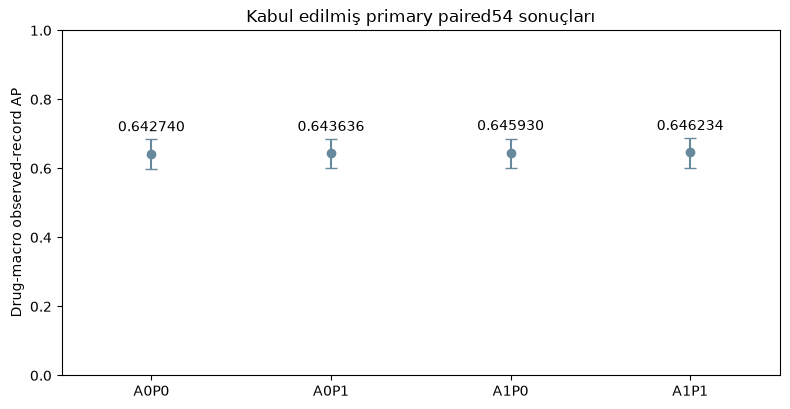

,protocol,contrast,estimate,CI95_low,CI95_high
0,primary,atom_P0,0.003189,0.000398,0.006675
3,primary,atom_P1,0.002598,0.000717,0.004763
6,primary,PPI_A0,0.000896,-0.001048,0.002651
9,primary,PPI_A1,0.000305,-0.002156,0.002497
12,primary,interaction,-0.000591,-0.003102,0.001541
15,primary,marginal_atom,0.002894,0.000773,0.005470
18,primary,marginal_PPI,0.000600,-0.001133,0.002316
42,stress,atom_P0,0.002730,-0.000045,0.006525
45,stress,atom_P1,0.002305,-0.000043,0.005478
48,stress,PPI_A0,0.000497,-0.001052,0.001818


In [3]:
m=pd.read_csv(T/'metrics_with_group_CI.csv')
a=m[m.protocol.eq('primary')&m.scope.eq('paired54')&m.metric.eq('drug_macro_AP')&m.model.isin(['A0P0','A0P1','A1P0','A1P1'])]
display(a[['model','estimate','CI95_low','CI95_high']])
fig,ax=plt.subplots(figsize=(8,4.2));xx=np.arange(4)
ax.errorbar(xx,a.estimate,yerr=np.vstack([a.estimate-a.CI95_low,a.CI95_high-a.estimate]),fmt='o',capsize=4,color='#66899b')
ax.set_xticks(xx,a.model);ax.set(ylabel='Drug-macro observed-record AP',ylim=(0,1),xlim=(-.5,3.5),title='Kabul edilmiş primary paired54 sonuçları')
for i,r in enumerate(a.itertuples()):ax.text(i,r.estimate+.065,f'{r.estimate:.6f}',ha='center')
plt.tight_layout();plt.savefig(F/'01_preserved_primary_AP.png',dpi=160);plt.show()
effects=pd.read_csv(T/'factorial_contrasts_group_CI.csv')
display(effects[effects.scope.eq('paired54')&effects.metric.eq('drug_macro_AP')][['protocol','contrast','estimate','CI95_low','CI95_high']])

**Yorum:**Atom dalında küçük koşullu ana katkı korunur;stresin koşullu atom CI'ları sıfırı içerir. PPI veetkileşim katkısı gösterilemedi. B0/B1'e belirgin üstünlük sağlanamadı. CI sabitOOF'ye koşullu ve keşifseldir;dış doğrulama veya nedensellik değildir. Bu grafik yeni performans hesabı değil,korunmuş CSV'nin gösterimidir.

## 3. Kapsam ve durma noktası

,protocol,scope,model,semantics,inventory_drugs,scored_drugs,AP_evaluable_drugs,expected_scored_pairs,scored_pairs,excluded_comparison_keys,observed_positive_scored,unknown_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,scored_class_union,class_AUROC_evaluable,class_AUROC_NA
10,primary,paired54,A1P1,Observed SIDER record ranking proxy; unknown N...,62,54,54,13964,13964,0,3820,10144,5505,1685,306,256,50
19,primary,own61,A1P1,Observed SIDER record ranking proxy; unknown N...,62,61,61,18004,18004,0,4576,13428,6405,1829,350,293,57
30,stress,paired54,A1P1,Observed SIDER record ranking proxy; unknown N...,62,54,54,13890,13890,0,3751,10139,5505,1754,307,257,50
39,stress,own61,A1P1,Observed SIDER record ranking proxy; unknown N...,62,61,61,17970,17970,0,4569,13401,6405,1836,351,300,51


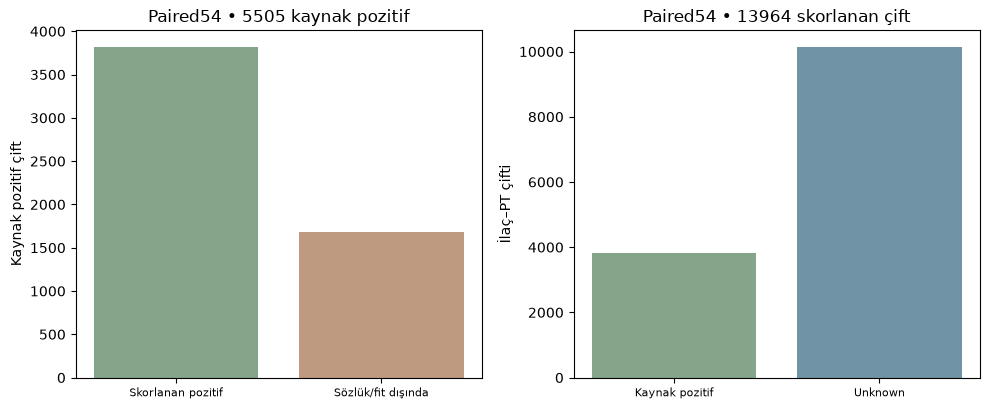

,0
source,docs/plan/ROADMAP_V7.md
source_sha256,c49907813583e6afbb139162ea0d3fc4136fb817947bf1...
exact_WP11_row,| **WP11** | Açıklanabilirlik: SHAP ≠ nedensel...
scope_review_only,True
implementation_started,False


In [4]:
coverage=pd.read_csv(T/'evaluation_coverage.csv');display(coverage[coverage.model.eq('A1P1')])
fig,axs=plt.subplots(1,2,figsize=(10,4.2))
axs[0].bar(['Skorlanan pozitif','Sözlük/fit dışında'],[3820,1685],color=['#85a58a','#bd9a80']);axs[0].set(title='Paired54 • 5505 kaynak pozitif',ylabel='Kaynak pozitif çift')
axs[1].bar(['Kaynak pozitif','Unknown'],[3820,10144],color=['#85a58a','#7093a6']);axs[1].set(title='Paired54 • 13964 skorlanan çift',ylabel='İlaç–PT çifti')
for ax in axs:ax.tick_params(axis='x',labelsize=8)
plt.tight_layout();plt.savefig(F/'02_preserved_source_coverage.png',dpi=160);plt.show()
scope=json.loads((Q/'WP11_roadmap_scope.json').read_text(encoding='utf-8'));display(pd.DataFrame([scope]).T)


**Yorum:**1685 kapsam dışı pozitif bütün62 ilacın yanlış-negatif sayısı değildir. Unknown çiftler doğrulanmış biyolojik negatif değildir.62 ilaç/1061 kaynakPT/6416 pozitif,Methenamine abstention,QC veNA kararları korunur. Klinik risk,hasta güvenliği veya nedensellik iddiası yoktur.

WP11'in yol haritasındaki konusu kimya baseline local/global SHAP vekoşullu protein/kenar açıklamalarıdır. Bu notebook hiçbir açıklama değeri üretmez;yalnız kapsam satırını gösterir. [Hazırlık notu](../reports/WP11_PREPARATION_DECISION.md) onay bekleyen seçimleri açıklar. **WP10 kapanır;WP11 uygulaması,yeni model veya yeni eğitim başlamadan durulur.**